In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models

print(tf.__version__)

2.21.0


In [ ]:
# Load MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Freeze the pretrained model
base_model.trainable = False

In [5]:
base_model.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [6]:
print("Total layers:", len(base_model.layers))
print("Trainable:", base_model.trainable)

Total layers: 154
Trainable: False


In [ ]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:
print("Total parameters:", model.count_params())

print(
    "Trainable parameters:",
    sum(
        tf.size(v).numpy()
        for v in model.trainable_variables
    )
)

Total parameters: 2259265
Trainable parameters: 1281


In [11]:
import tensorflow as tf
import zipfile
import os

url = "https://download.mlcc.google.com/mledu-datasets/cats_and_dogs_filtered.zip"

zip_path = tf.keras.utils.get_file(
    "cats_and_dogs_filtered_v2.zip",
    origin=url,
    extract=False
)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(os.path.dirname(zip_path))

extract_path = os.path.join(
    os.path.dirname(zip_path),
    "cats_and_dogs_filtered"
)

print("Dataset downloaded successfully!")
print("Dataset path:", extract_path)

68606236/68606236 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Dataset downloaded successfully!
Dataset path: /root/.keras/datasets/cats_and_dogs_filtered


In [12]:
train_dir = os.path.join(extract_path, "train")
val_dir = os.path.join(extract_path, "validation")

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary"
)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.


In [13]:
print(train_ds.class_names)

['cats', 'dogs']


In [14]:
# Preprocessing
preprocess = tf.keras.applications.mobilenet_v2.preprocess_input
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.map(
    lambda x, y: (preprocess(x), y),
    num_parallel_calls=AUTOTUNE
)

val_ds = val_ds.map(
    lambda x, y: (preprocess(x), y),
    num_parallel_calls=AUTOTUNE
)

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

In [15]:
for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)

Images shape: (32, 224, 224, 3)
Labels shape: (32, 1)


In [16]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step - accuracy: 0.9105 - loss: 0.2477 - val_accuracy: 0.9790 - val_loss: 0.0858
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 87s 1s/step - accuracy: 0.9755 - loss: 0.0800 - val_accuracy: 0.9840 - val_loss: 0.0569
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 86s 1s/step - accuracy: 0.9840 - loss: 0.0572 - val_accuracy: 0.9860 - val_loss: 0.0468
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 68s 1s/step - accuracy: 0.9870 - loss: 0.0451 - val_accuracy: 0.9870 - val_loss: 0.0413
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 86s 1s/step - accuracy: 0.9885 - loss: 0.0415 - val_accuracy: 0.9850 - val_loss: 0.0369


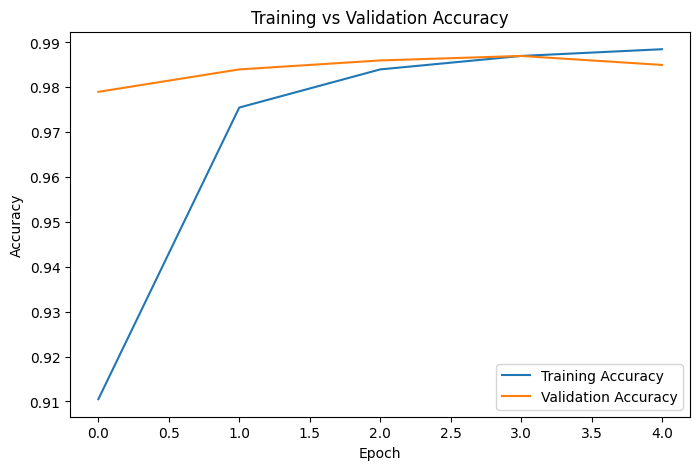

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

In [18]:
val_loss, val_accuracy = model.evaluate(val_ds)

print("Validation Accuracy:", val_accuracy * 100, "%")

32/32 ━━━━━━━━━━━━━━━━━━━━ 23s 705ms/step - accuracy: 0.9850 - loss: 0.0369
Validation Accuracy: 98.50000143051147 %


**Fine Tuning**

In [ ]:
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

In [20]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [21]:
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3
)

Epoch 1/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 111s 2s/step - accuracy: 0.9900 - loss: 0.0300 - val_accuracy: 0.9890 - val_loss: 0.0268
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.9965 - loss: 0.0136 - val_accuracy: 0.9920 - val_loss: 0.0249
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 101s 2s/step - accuracy: 0.9985 - loss: 0.0068 - val_accuracy: 0.9910 - val_loss: 0.0238


In [22]:
model.save("cats_dogs_mobilenetv2.keras")

In [27]:
from google.colab import files

uploaded = files.upload()

Saving Pyari_cat.jpg to Pyari_cat.jpg


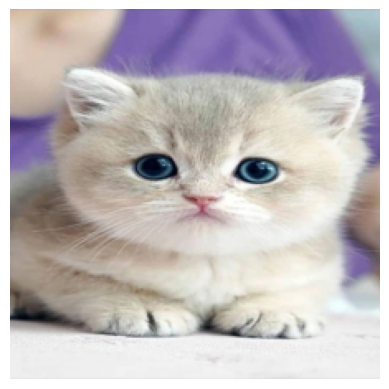

In [28]:
import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt

image_path = list(uploaded.keys())[0]

img = Image.open(image_path).convert("RGB")
img = img.resize((224, 224))

plt.imshow(img)
plt.axis("off")
plt.show()

In [29]:
img_array = np.array(img)

img_array = tf.keras.applications.mobilenet_v2.preprocess_input(
    img_array
)

img_array = np.expand_dims(img_array, axis=0)
print("Image shape:", img_array.shape)

Image shape: (1, 224, 224, 3)


In [30]:
prediction = model.predict(img_array)

probability = prediction[0][0]

if probability >= 0.5:
    print("Prediction: Dog")
    print("Confidence:", probability * 100, "%")
else:
    print("Prediction: Cat")
    print("Confidence:", (1 - probability) * 100, "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Prediction: Cat
Confidence: 99.999306 %


32/32 ━━━━━━━━━━━━━━━━━━━━ 28s 795ms/step


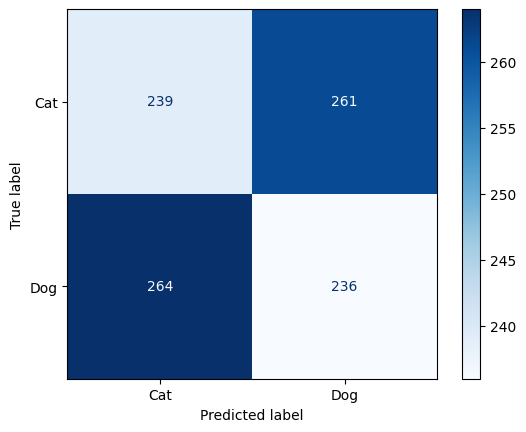

In [31]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_true = np.concatenate([
    labels.numpy().flatten()
    for images, labels in val_ds
])

predictions = model.predict(val_ds)

y_pred = (predictions.flatten() >= 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

display.plot(cmap="Blues")
plt.show()

Accuracy: 0.991
              precision    recall  f1-score   support

         Cat       0.99      0.99      0.99       500
         Dog       0.99      0.99      0.99       500

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000



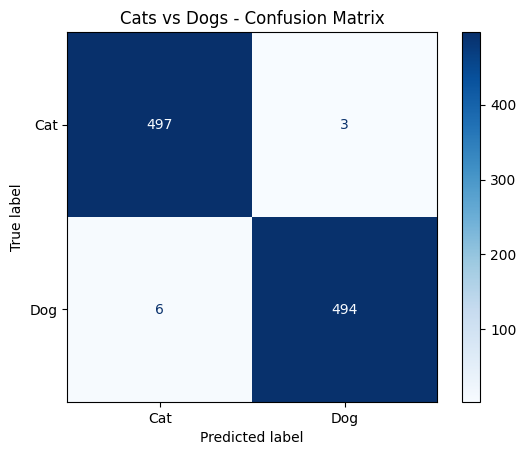

In [ ]:
import numpy as np
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

y_true = []
y_pred = []

for images, labels in val_ds:
    probabilities = model(images, training=False).numpy().flatten()

    predictions = (probabilities >= 0.5).astype(int)

    y_true.extend(labels.numpy().flatten().astype(int))
    y_pred.extend(predictions)

print("Accuracy:", accuracy_score(y_true, y_pred))

# Precision, Recall and F1-score for both classes
print(classification_report(
    y_true,
    y_pred,
    target_names=["Cat", "Dog"]
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

display.plot(cmap="Blues")
plt.title("Cats vs Dogs - Confusion Matrix")
plt.show()

In [34]:
wrong_images = []
wrong_actual = []
wrong_predicted = []

for images, labels in val_ds:
    probabilities = model(images, training=False).numpy().flatten()
    predictions = (probabilities >= 0.5).astype(int)

    actual = labels.numpy().flatten().astype(int)

    wrong_indices = np.where(predictions != actual)[0]

    for idx in wrong_indices:
        wrong_images.append(images[idx].numpy())
        wrong_actual.append(actual[idx])
        wrong_predicted.append(predictions[idx])

print("Total incorrect predictions:", len(wrong_images))

Total incorrect predictions: 9


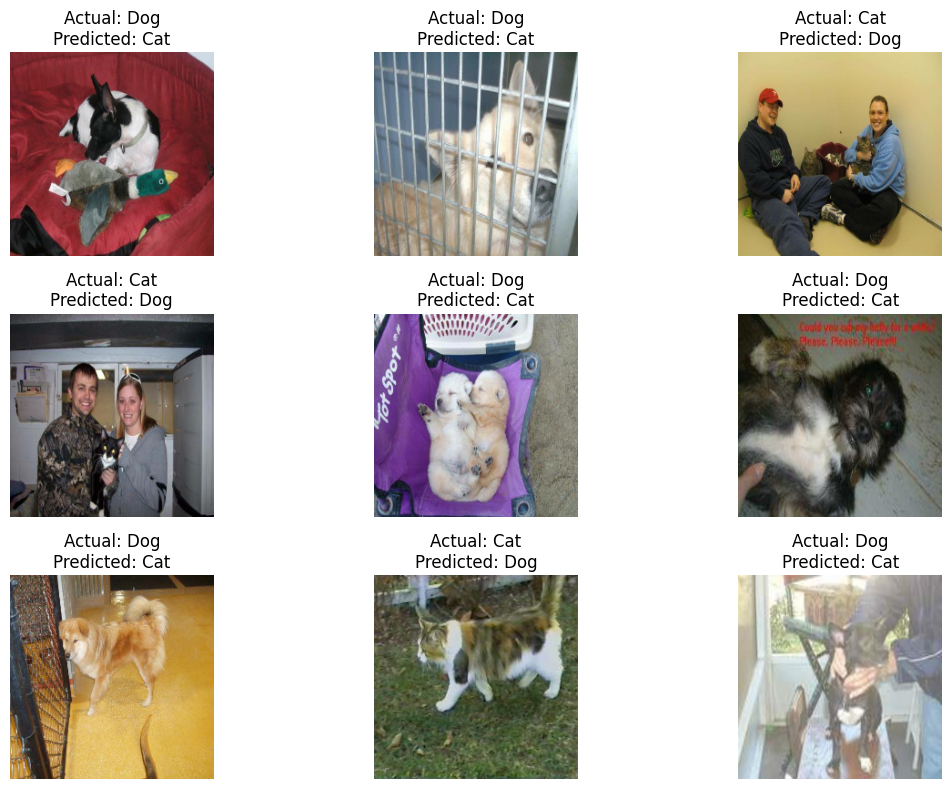

In [35]:
plt.figure(figsize=(12, 8))

for i in range(len(wrong_images)):
    plt.subplot(3, 3, i + 1)

    # Convert pixels back to display range
    image = (wrong_images[i] + 1) / 2
    image = np.clip(image, 0, 1)

    plt.imshow(image)

    actual = "Cat" if wrong_actual[i] == 0 else "Dog"
    predicted = "Cat" if wrong_predicted[i] == 0 else "Dog"

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [1]:
%%writefile app.py

import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image

@st.cache_resource
def load_model():
    return tf.keras.models.load_model(
        "cats_dogs_mobilenetv2.keras"
    )

model = load_model()

st.title("🐱 Cats vs Dogs Classifier")
st.write("Upload an image to classify it as a cat or dog.")

uploaded_file = st.file_uploader(
    "Upload an image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:

    image = Image.open(uploaded_file).convert("RGB")
    st.image(image, caption="Uploaded Image", width="stretch")

    if st.button("Predict"):

        resized = image.resize((224, 224))
        image_array = np.array(resized, dtype=np.float32)

        image_array = tf.keras.applications.mobilenet_v2.preprocess_input(
            image_array
        )

        image_array = np.expand_dims(image_array, axis=0)

        probability = float(
            model.predict(image_array, verbose=0)[0][0]
        )

        if probability >= 0.5:
            st.success("Prediction: Dog 🐶")
            st.metric("Dog confidence", f"{probability * 100:.2f}%")
        else:
            st.success("Prediction: Cat 🐱")
            st.metric("Cat confidence", f"{(1-probability) * 100:.2f}%")

Writing app.py


In [2]:
import os

print(os.path.exists("cats_dogs_mobilenetv2.keras"))

False


In [3]:
%%writefile requirements.txt

tensorflow
streamlit
numpy
pillow

Writing requirements.txt


In [4]:
import os

print(os.listdir())

['.config', 'app.py', 'requirements.txt', 'sample_data']


In [5]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 21.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 56.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [6]:
!streamlit run app.py &>/content/streamlit.log &